# ReplaceMe: замена блоков ViT с помощью МНК

**CIFAR-100 · ViT-L/16 · 24 блока.** Заменим блоки **14, 18, 22** и сравним качество с простым удалением. Нумерация блоков — с нуля; цель — потеря accuracy **<2 п.п.**

Ноутбук содержит готовые измерения. `RUN_GPU = True` повторяет основной эксперимент; для просмотра результатов GPU не нужен. Для повторного выполнения ячеек держите рядом файл `seminar_results.json`.

## Линейная замена блока

Удаляем блок $j$ и изменяем последнюю линейную проекцию MLP блока $j-1$. Обозначим:

- $H$ — признаки после GELU в этом MLP, размерность 4096;
- $Y$ — residual после attention сохранённого блока;
- $L$ — выход удаляемого блока;
- $A=[H,1]$, $B=L-Y$, $U_0=[W^\top;b]$.

Выход сохранённого блока должен приблизить $L$: $Y+AU\approx L$. Решаем регуляризованный МНК:

$$U^*=\arg\min_U\|AU-B\|_F^2+\lambda\|U-U_0\|_F^2,$$
$$U^*=(A^\top A+\lambda I)^{-1}(A^\top B+\lambda U_0).$$

В коде обращение матрицы заменено решением через Cholesky в FP64. Используем $\lambda=10^{-3}\operatorname{mean}(\operatorname{diag}(A^\top A))$.

**Это расширение ReplaceMe:** исходная выходная коррекция ограничивает параметры формой $W_{new}=T^\top W$; здесь подбирается вся affine-проекция $U$. Она записывается в существующие weight и bias. Дополнительных слоёв и градиентного дообучения нет.

## Данные

Checkpoint: `jialicheng/cifar100_vit-large`. Seed — 42.

| Выборка | Изображений | Назначение |
|---|---:|---|
| Calibration из train | 2048 | МНК без меток, все 197 токенов |
| Validation из train | 1000 | Профиль отдельных блоков |
| Test | 10 000 | Основной результат и абляция числа блоков |

Calibration и validation не пересекаются. На каждом этапе используются те же calibration-изображения; активации собираются заново. План выбран по validation. Test уже использовался в исследовании; checkpoint мог видеть train при обучении.

Для повторения: CUDA PyTorch, `transformers==4.46.3`, `datasets==3.2.0`, NumPy, Pillow, Matplotlib и IPython.

In [1]:
import copy
import json
from pathlib import Path
import math
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display

RUN_GPU = False
MODEL_ID = 'jialicheng/cifar100_vit-large'
MODEL_REVISION = '722bbe34aab672f2ade7be53bb7e2fa8bea6fb57'
DATASET_ID = 'uoft-cs/cifar100'
DATASET_REVISION = 'aadb3af77e9048adbea6b47c21a81e47dd092ae5'
REMOVED_BLOCKS = [14, 18, 22]
CALIBRATION_IMAGES = 2048
RIDGE = 0.001
SEED = 42

torch.set_num_threads(4)
torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.benchmark = False

In [2]:
def batches(dataset, indices, processor, batch_size, device):
    for start in range(0, len(indices), batch_size):
        rows = dataset.select(indices[start:start + batch_size])
        x = processor(images=rows['img'], return_tensors='pt')['pixel_values'].to(device)
        yield x, torch.tensor(rows['fine_label'], device=device)

@torch.inference_mode()
def evaluate(model, dataset, indices, processor, batch_size, device):
    predictions, targets, losses = [], [], []
    for x, y in batches(dataset, indices, processor, batch_size, device):
        logits = model(x).logits
        predictions.extend(logits.argmax(-1).cpu().tolist())
        targets.extend(y.cpu().tolist())
        losses.extend(F.cross_entropy(logits, y, reduction='none').cpu().tolist())
    correct = np.equal(predictions, targets)
    return {'accuracy': float(correct.mean()), 'correct': int(correct.sum()),
            'n': len(targets), 'cross_entropy': float(np.mean(losses)),
            'predictions': predictions, 'targets': targets}

def paired_interval(first, second, seed=42):
    a = np.equal(first['predictions'], first['targets']).astype(float)
    b = np.equal(second['predictions'], second['targets']).astype(float)
    delta = b - a
    rng = np.random.default_rng(seed)
    boot = [rng.choice(delta, len(delta), replace=True).mean() for _ in range(2000)]
    return {'delta_accuracy': float(delta.mean()), 'ci95': np.quantile(boot, [.025, .975]).tolist(),
            'method': 'paired image bootstrap, 2000 resamples; conditional on this trained checkpoint'}

def prune_block(model, block, count=1):
    """Physically remove [block, block+count); block 0 has no predecessor."""
    layers = model.vit.encoder.layer
    if count < 1 or not 1 <= block < len(layers) or block + count > len(layers):
        raise ValueError('positive block range must have a predecessor and fit the encoder')
    model.vit.encoder.layer = torch.nn.ModuleList(
        [layer for i, layer in enumerate(layers) if not block <= i < block + count])
    model.config.num_hidden_layers = len(model.vit.encoder.layer)

## Сбор активаций и решение МНК

Hooks считывают $H$, $Y$ и $L$. Накапливаем только $A^\top A$ и $A^\top B$, поэтому хранить все 403 456 строк в памяти не требуется. После решения переносим коэффициенты в существующий MLP.

In [3]:
@torch.inference_mode()
def collect_projection_stats(model, block, batch_iterator, count=1):
    layers=model.vit.encoder.layer
    if count<1 or block<1 or block+count>len(layers):
        raise ValueError('Range must fit and have a predecessor')
    dense=layers[block-1].output.dense
    if dense.bias is None:raise ValueError('Expected an affine MLP output projection')
    captured={}
    handles=[dense.register_forward_pre_hook(lambda m,a:captured.update(h=a[0].detach())),
             layers[block-1].output.register_forward_pre_hook(lambda m,a:captured.update(y=a[1].detach())),
             layers[block+count-1].register_forward_hook(lambda m,a,o:captured.update(last=o[0].detach()))]
    gram=cross=None
    rows=images=0
    try:
        for x,_ in batch_iterator:
            model(x)
            h=captured['h'].reshape(-1,dense.in_features).double()
            b=(captured['last'].double()-captured['y'].double()).reshape(-1,dense.out_features)
            a=torch.cat([h,torch.ones(len(h),1,device=h.device,dtype=h.dtype)],1)
            if gram is None:
                gram=torch.zeros(a.shape[1],a.shape[1],device=a.device,dtype=a.dtype)
                cross=torch.zeros(a.shape[1],b.shape[1],device=a.device,dtype=a.dtype)
            gram.addmm_(a.T,a)
            cross.addmm_(a.T,b)
            rows+=len(a);images+=len(x)
    finally:
        for handle in handles:handle.remove()
        captured.clear()
    if gram is None:raise ValueError('No calibration batches supplied')
    prior=torch.cat([dense.weight.detach().T,dense.bias.detach()[None,:]],0).double()
    return gram,cross,prior,{'rows':rows,'images':images,'tokens_per_image':rows/images,
        'features_with_bias':dense.in_features+1,'outputs':dense.out_features}

@torch.no_grad()
def solve_projection(gram, cross, prior, ridge):
    if not math.isfinite(ridge) or ridge <= 0:
        raise ValueError('Positive finite ridge is required for the normal-equation solve')
    if (gram.ndim!=2 or gram.shape[0]!=gram.shape[1] or not gram.shape[0]
            or cross.ndim!=2 or cross.shape[0]!=gram.shape[0] or prior.shape!=cross.shape):
        raise ValueError('Incompatible sufficient-statistic or prior shapes')
    gram=gram.detach().double()
    cross=cross.detach().to(device=gram.device,dtype=torch.float64)
    prior=prior.detach().to(device=gram.device,dtype=torch.float64)
    if not all(bool(torch.isfinite(x).all()) for x in [gram,cross,prior]):
        raise ValueError('Non-finite statistics')
    scale=float(torch.diagonal(gram).mean())
    penalty=ridge*(scale if scale>0 else 1.)
    system=(gram+gram.T)*.5+penalty*torch.eye(len(gram),device=gram.device,dtype=gram.dtype)
    rhs=cross+penalty*prior
    factor=torch.linalg.cholesky(system)
    fitted=torch.cholesky_solve(rhs,factor).clone().contiguous()
    residual=float(torch.linalg.vector_norm(system@fitted-rhs))/max(float(torch.linalg.vector_norm(rhs)),1e-30)
    if not torch.isfinite(fitted).all() or residual>1e-8:
        raise ArithmeticError('Projection solve failed its FP64 residual check')
    return fitted,{'ridge':ridge,'lambda':penalty,'feature_dim_with_bias':len(gram),
        'relative_system_residual':residual,
        'condition_upper_bound':(float(torch.trace(gram))+penalty)/penalty,
        'solver':'FP64 sufficient statistics + positive ridge + Cholesky',
        'method':'full MLP projection refit; extension beyond output-transform ReplaceMe'}

@torch.no_grad()
def install_projection(dense, coefficients):
    if coefficients.shape!=(dense.in_features+1,dense.out_features):
        raise ValueError('Expected [in_features+1,out_features] including intercept')
    if dense.bias is None:
        raise ValueError('A bias parameter is required for the affine refit')
    dense.weight.copy_(coefficients[:-1].T.to(dense.weight))
    dense.bias.copy_(coefficients[-1].to(dense.bias))

## Последовательная замена трёх блоков

Сначала удаляется исходный блок 14, затем 18, затем 22. Их текущие индексы — 14, 17 и 20: список исходных ID позволяет корректно учитывать сдвиги. Каждый новый fit строится на уже сжатой модели.

In [4]:
def compress(model, train, processor, calibration_indices, removed_blocks, device):
    compressed = copy.deepcopy(model).eval()
    original_ids = list(range(len(compressed.vit.encoder.layer)))
    for original_block in removed_blocks:
        block = original_ids.index(original_block)
        iterator = batches(train, calibration_indices, processor, 8, device)
        gram, cross, prior, _ = collect_projection_stats(compressed, block, iterator)
        coefficients, _ = solve_projection(gram, cross, prior, RIDGE)
        del gram, cross, prior
        install_projection(compressed.vit.encoder.layer[block - 1].output.dense, coefficients)
        prune_block(compressed, block)
        original_ids.pop(block)
    assert original_ids == [i for i in range(len(model.vit.encoder.layer))
                            if i not in removed_blocks]
    return compressed

In [5]:
def run_experiment():
    from datasets import load_dataset
    from transformers import AutoImageProcessor, ViTForImageClassification

    if not torch.cuda.is_available():
        raise RuntimeError('Для полного эксперимента включите CUDA GPU.')
    processor = AutoImageProcessor.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, use_fast=False)
    original = ViTForImageClassification.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, attn_implementation='sdpa').cuda().eval()
    data = load_dataset(DATASET_ID, revision=DATASET_REVISION)
    assert [original.config.id2label[i] for i in range(100)] == data['train'].features['fine_label'].names
    calibration = np.random.default_rng(SEED).permutation(len(data['train'])).tolist()[:CALIBRATION_IMAGES]
    compressed = compress(original, data['train'], processor, calibration, REMOVED_BLOCKS, 'cuda')
    deleted = copy.deepcopy(original)
    for block in sorted(REMOVED_BLOCKS, reverse=True):
        prune_block(deleted, block)
    models = {'original': original, 'delete': deleted, 'replaceme_ls': compressed}
    scores = {name: evaluate(model, data['test'], list(range(len(data['test']))),
                             processor, 16, 'cuda') for name, model in models.items()}
    loss = 100 * (scores['original']['correct'] - scores['replaceme_ls']['correct']) / len(data['test'])
    return {
        'test': {name: {k: s[k] for k in ['accuracy', 'correct', 'n']} for name, s in scores.items()},
        'parameters': {name: sum(p.numel() for p in model.parameters()) for name, model in models.items()},
        'test_loss_pp': loss,
        'paired_ls_vs_delete': paired_interval(scores['delete'], scores['replaceme_ls']),
        'removed_original_blocks': REMOVED_BLOCKS,
    }

## Результат на test

Исходная модель, удаление и МНК оцениваются на одинаковых 10 000 изображениях. Парный bootstrap-интервал относится к выбранной паре моделей и не учитывает подбор блоков.

In [6]:
measurements = json.loads(Path('seminar_results.json').read_text())
result = run_experiment() if RUN_GPU else measurements['main']
names = {'original': 'Исходная', 'delete': 'Простое удаление', 'replaceme_ls': 'МНК'}
rows = ['| Модель | Accuracy | Верных / 10 000 | Параметры |', '|---|---:|---:|---:|']
for name, title in names.items():
    score = result['test'][name]
    rows.append(f"| {title} | {100*score['accuracy']:.2f}% | {score['correct']} | {result['parameters'][name]:,} |")
display(Markdown('\n'.join(rows)))
gain = result['paired_ls_vs_delete']
low, high = np.array(gain['ci95']) * 100
print(f"Потеря к исходной модели: {result['test_loss_pp']:.2f} п.п.")
print(f"Выигрыш над удалением: {100*gain['delta_accuracy']:.2f} п.п.; 95% CI [{low:.2f}; {high:.2f}]")

| Модель | Accuracy | Верных / 10 000 | Параметры |
|---|---:|---:|---:|
| Исходная | 93.56% | 9356 | 303,404,132 |
| Простое удаление | 87.57% | 8757 | 265,615,460 |
| МНК | 92.07% | 9207 | 265,615,460 |

Потеря к исходной модели: 1.49 п.п.
Выигрыш над удалением: 4.50 п.п.; 95% CI [3.95; 5.06]


## Сколько блоков можно удалить?

Порядок **14 → 18 → 22 → 23** фиксирован. МНК применяется последовательно с теми же 2048 изображениями и ridge; все точки оценены на полном test. Пунктир — граница потери 2 п.п.

На четвёртом шаге проекция блока 21 переоценивается, чтобы компенсировать также блок 23. Кривая характеризует этот порядок, а не лучшие наборы каждой длины.

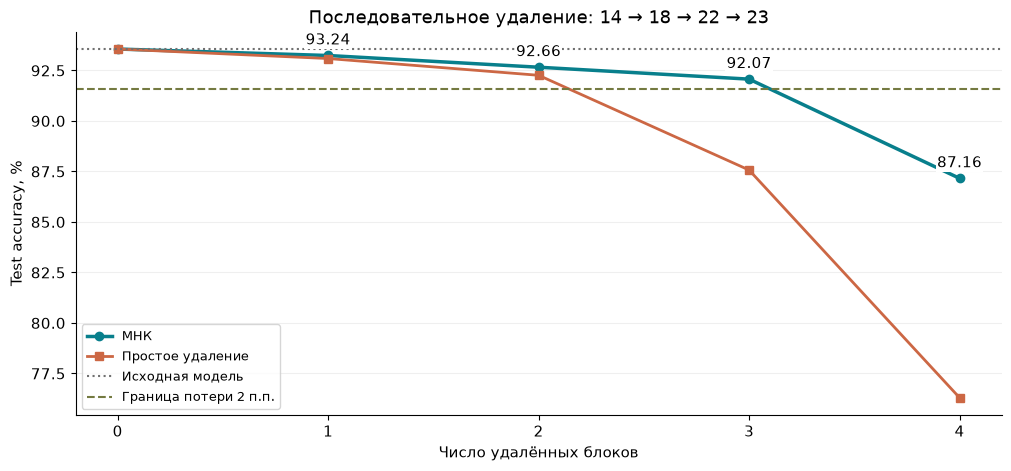

| Блоков | Исходные ID | Удаление | МНК | Потеря МНК | Выигрыш МНК |
|---:|---|---:|---:|---:|---:|
| 0 | — | 93.56% | 93.56% | 0.00 п.п. | 0.00 п.п. |
| 1 | 14 | 93.09% | 93.24% | 0.32 п.п. | 0.15 п.п. |
| 2 | 14, 18 | 92.26% | 92.66% | 0.90 п.п. | 0.40 п.п. |
| 3 | 14, 18, 22 | 87.57% | 92.07% | 1.49 п.п. | 4.50 п.п. |
| 4 | 14, 18, 22, 23 | 76.30% | 87.16% | 6.40 п.п. | 10.86 п.п. |

Для этого порядка условие потери **<2 п.п.** выполняется при числе удалённых блоков: 0, 1, 2, 3. Большой выигрыш над удалением сам по себе не гарантирует сохранения качества.

In [7]:
import matplotlib.pyplot as plt

ablation = measurements['ablations']
depth = ablation['depth']
x = [r['removed_count'] for r in depth]
ls = np.array([r['ls_accuracy'] for r in depth]) * 100
naive = np.array([r['delete_accuracy'] for r in depth]) * 100
baseline = 100 * ablation['test_baseline_accuracy']

with plt.rc_context({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False}):
    fig, ax = plt.subplots(figsize=(10, 4.6), layout='constrained')
    ax.plot(x, ls, 'o-', color='#087f8c', linewidth=2.5, label='МНК')
    ax.plot(x, naive, 's-', color='#cc6744', linewidth=2, label='Простое удаление')
    ax.axhline(baseline, color='#707070', linestyle=':', label='Исходная модель')
    ax.axhline(baseline - 2, color='#747a41', linestyle='--', label='Граница потери 2 п.п.')
    for k, value in zip(x[1:], ls[1:]):
        ax.annotate(f'{value:.2f}', (k, value), xytext=(0, 8), textcoords='offset points', ha='center',
                    bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
    ax.set(xticks=x, xlabel='Число удалённых блоков', ylabel='Test accuracy, %',
           title='Последовательное удаление: 14 → 18 → 22 → 23')
    ax.grid(axis='y', alpha=.2)
    ax.legend(loc='best', fontsize=9)
    plt.show()

table = ['| Блоков | Исходные ID | Удаление | МНК | Потеря МНК | Выигрыш МНК |',
         '|---:|---|---:|---:|---:|---:|']
for row, a, b in zip(depth, naive, ls):
    ids = ', '.join(map(str, row['removed_original_blocks'])) or '—'
    table.append(f"| {row['removed_count']} | {ids} | {a:.2f}% | {b:.2f}% | {baseline-b:.2f} п.п. | {b-a:.2f} п.п. |")
display(Markdown('\n'.join(table)))
test_n = ablation['test_n']
lost_correct = np.rint((baseline - ls) * test_n / 100).astype(int)
passing = [str(k) for k, lost in zip(x, lost_correct) if 100 * lost < 2 * test_n]
display(Markdown('Для этого порядка условие потери **<2 п.п.** выполняется при числе удалённых блоков: '
                 + ', '.join(passing) + '. Большой выигрыш над удалением сам по себе не гарантирует сохранения качества.'))

## Какие блоки заменяемы?

- **$1-\cos(x_j,x_{j+1})$:** изменение представлений на 256 calibration-изображениях, по всем токенам и отдельно CLS.
- **Потеря accuracy:** удаление или замена одного блока исходной модели; оценка на validation из 1000 изображений.
- **Выигрыш МНК:** разность accuracy МНК и удаления.

Все fit используют 2048 изображений. Для блока 0 МНК не определён: нет предыдущего MLP. Подсвечены блоки основного опыта. Профиль потерь дополнительно увеличен около порога 2 п.п.

Одиночные эффекты не складываются при совместном удалении. Шаг validation accuracy — 0,1 п.п.; небольшие различия могут быть шумом.

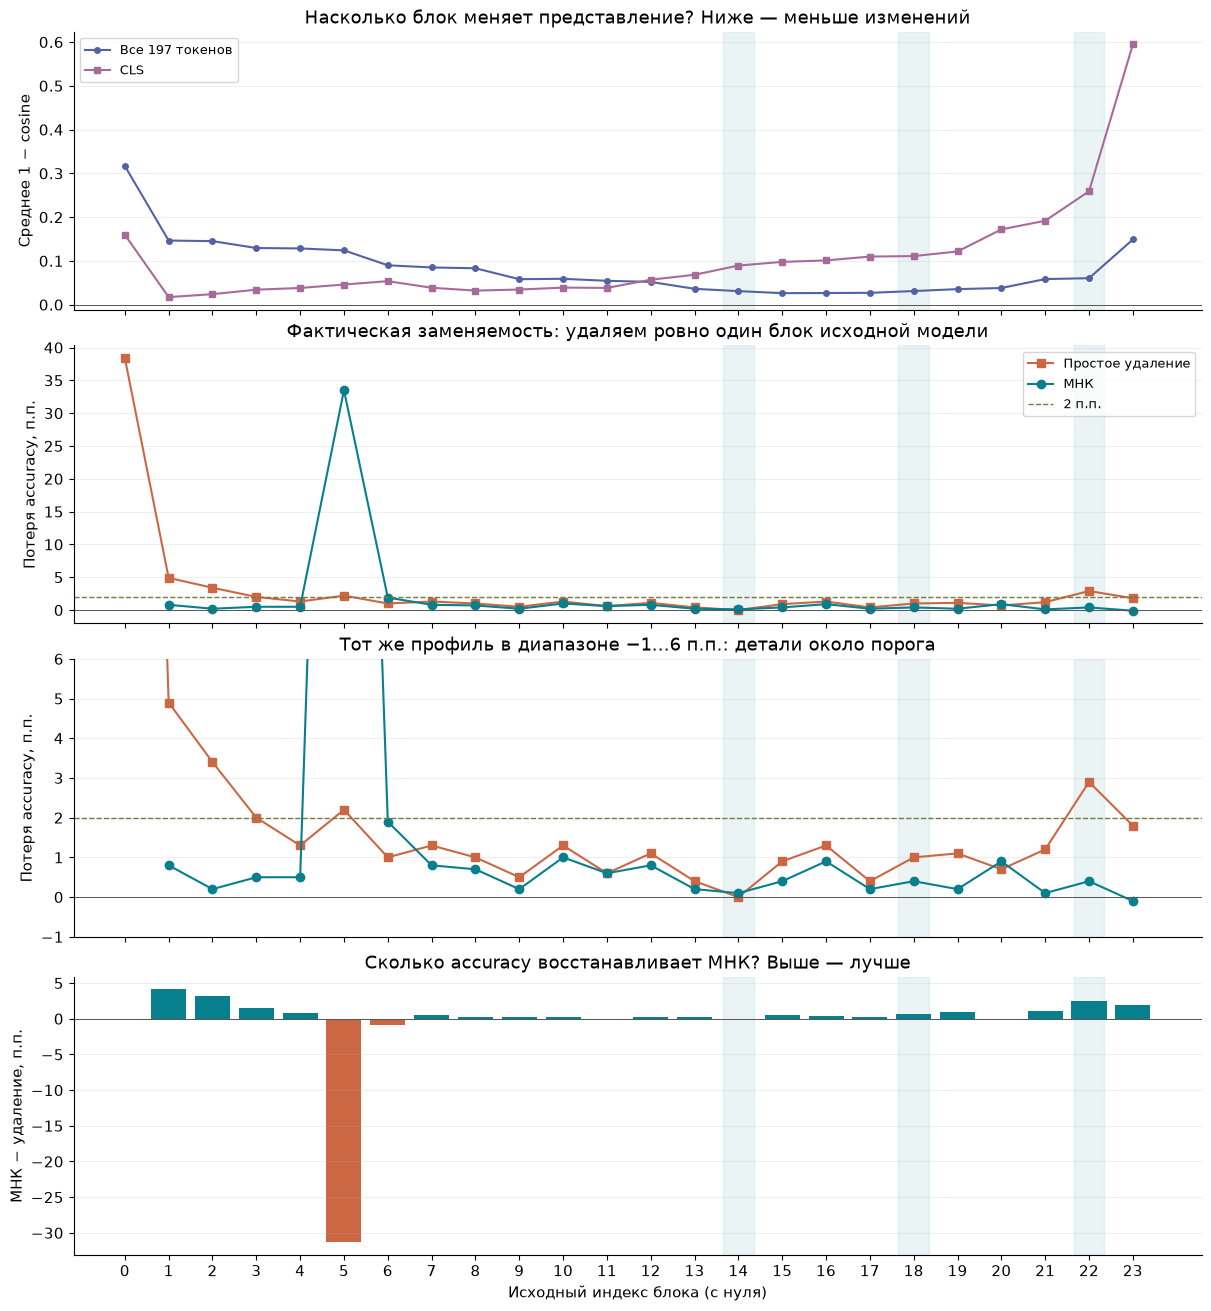

Исходная accuracy на validation: **93.90%**. Подсвечены блоки 14, 18, 22 из основного опыта. Для блока 0 МНК не определён: отсутствует предыдущий MLP.

In [8]:
profile = sorted(ablation['profile'], key=lambda row: row['block'])
cosine = sorted(ablation['cosine'], key=lambda row: row['block'])
blocks = np.array([r['block'] for r in profile])
loss_delete = np.array([r['delete_loss_pp'] for r in profile])
loss_ls = np.array([np.nan if r['ls_loss_pp'] is None else r['ls_loss_pp'] for r in profile])
gain = loss_delete - loss_ls

with plt.rc_context({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False}):
    fig, axes = plt.subplots(4, 1, figsize=(12, 13), sharex=True, layout='constrained')
    axes[0].plot(blocks, [r['all_tokens_distance'] for r in cosine], 'o-',
                 color='#5262a3', markersize=4, label='Все 197 токенов')
    axes[0].plot(blocks, [r['cls_distance'] for r in cosine], 's-',
                 color='#a66b9a', markersize=4, label='CLS')
    axes[0].set(ylabel='Среднее 1 − cosine', title='Насколько блок меняет представление? Ниже — меньше изменений')
    axes[0].legend(fontsize=9)
    axes[1].plot(blocks, loss_delete, 's-', color='#cc6744', label='Простое удаление')
    axes[1].plot(blocks, loss_ls, 'o-', color='#087f8c', label='МНК')
    axes[1].axhline(2, color='#747a41', linestyle='--', linewidth=1, label='2 п.п.')
    axes[1].set(ylabel='Потеря accuracy, п.п.', title='Фактическая заменяемость: удаляем ровно один блок исходной модели')
    axes[1].legend(fontsize=9)
    axes[2].plot(blocks, loss_delete, 's-', color='#cc6744', label='Простое удаление')
    axes[2].plot(blocks, loss_ls, 'o-', color='#087f8c', label='МНК')
    axes[2].axhline(2, color='#747a41', linestyle='--', linewidth=1)
    axes[2].set(ylabel='Потеря accuracy, п.п.', ylim=(-1, 6),
                title='Тот же профиль в диапазоне −1…6 п.п.: детали около порога')
    axes[3].bar(blocks, gain, color=['#087f8c' if v >= 0 else '#cc6744' for v in gain])
    axes[3].set(ylabel='МНК − удаление, п.п.', xlabel='Исходный индекс блока (с нуля)',
                title='Сколько accuracy восстанавливает МНК? Выше — лучше')
    for ax in axes:
        ax.axhline(0, color='#555555', linewidth=.7)
        ax.grid(axis='y', alpha=.2)
        for block in REMOVED_BLOCKS:
            ax.axvspan(block - .35, block + .35, color='#087f8c', alpha=.08)
    axes[3].set_xticks(blocks)
    plt.show()

display(Markdown(f"Исходная accuracy на validation: **{100*ablation['validation_baseline_accuracy']:.2f}%**. "
                 "Подсвечены блоки 14, 18, 22 из основного опыта. "
                 "Для блока 0 МНК не определён: отсутствует предыдущий MLP."))

**Локальная ошибка не гарантирует итоговую accuracy.** Для блока 5 МНК теряет 33,5 п.п., а удаление — 2,2 п.п. Поэтому заменяемость проверяем по качеству всей модели, а не только по сходству активаций.

[Статья ReplaceMe, NeurIPS 2025](https://proceedings.neurips.cc/paper_files/paper/2025/file/1c10d0c087c14689628124bbc8fa69f6-Paper-Conference.pdf) · [Код авторов](https://github.com/mts-ai/ReplaceMe) · [Checkpoint](https://huggingface.co/jialicheng/cifar100_vit-large)

Статья содержит опыты с языковыми моделями и CLIP. Этот notebook — адаптация с полной проекцией MLP для fine-tuned ViT на CIFAR-100.